# Milestone 3 - Moteur d'optimisation des livraisons

**But :** pour chaque couple fournisseur × usine, choisir les **jours de livraison** et y regrouper les besoins (anticipation de 7 jours au plus) pour **minimiser le coût de transport**, puis en déduire le **profil** de livraison (RG05, RG07).

**Entrées :** `data/consolidated_dataset.csv` (Milestone 1, besoins nettoyés avec distance), `docs/rate_sheet.csv` (grille tarifaire), `data/baseline_deliveries.csv` (Milestone 2, situation actuelle à battre).

## Modèle mathématique

### Ensembles

| Symbole | Signification | Règle |
| :--- | :--- | :--- |
| $C$ | couples $c = (f, u)$ fournisseur × usine ayant au moins un besoin (180) | RG01 |
| $L_c$ | lignes de besoin du couple $c$ : un matériau $m$, un quai, un jour de besoin $i_l$ | |
| $J$ | jours de livraison possibles : jours ouvrés hors fériés allemands, du premier besoin − 7 jours au dernier besoin | RG10 |
| $A_l \subseteq J$ | jours où la ligne $l$ peut arriver : $i_l - 7 \le j \le i_l$ (jours calendaires) | RG03 |
| $D$ | jours de la semaine (lundi … vendredi) ; $wd(j)$ = jour de la semaine de $j$ | RG05 |
| $K$ | tranches de poids de la grille (≤ 50 kg, …, ≤ 4 000 kg, > 4 000 kg) | RG11 |

### Paramètres

| Symbole | Signification |
| :--- | :--- |
| $W_l$, $V_l$ | poids (kg) et volume (m³) de la ligne $l$ |
| $d_c$ | distance du fournisseur du couple $c$ (km) |
| $\bar w_k$ | borne haute de la tranche $k$ ; la dernière (> 4 000 kg) est bornée par la capacité $Q$ |
| $p_{c,k}$ | prix d'un camion du couple $c$ dans la tranche $k$ : $\text{base}(d_c, k) \times (1 + \text{marge}) \times \text{diesel}$ |
| $p^{\max}_c$ | prix d'un camion plein au **tarif forfaitaire** : $p^{\max}_c = p_{c,\bar k}$, où $\bar k$ est la dernière tranche de la grille (> 4 000 kg) ; le prix y est le même quel que soit le poids, jusqu'à $Q$ |
| $Q$, $\bar V$ | capacité d'un camion : 24 500 kg et 110,4 m³ (RG04) |
| $N$ | profil testé : au plus $N$ jours de livraison par semaine (1 à 5) |
| $\varepsilon$ | petite pénalité par jour de livraison (0,01 €) : à coût égal, on préfère moins de livraisons |

### Variables (toutes indexées par le couple $c$)

| Variable | Signification |
| :--- | :--- |
| $z_{c,l,j} \in \{0,1\}$ | la ligne $l$ du couple $c$ est livrée le jour $j \in A_l$ |
| $x_{c,j} \in \{0,1\}$ | le couple $c$ est livré le jour $j$ (une livraison = un couple × un jour, RG12) |
| $F_{c,j} \in \mathbb{N}$ | camions **pleins** du couple $c$ le jour $j$, facturés au forfait |
| $y_{c,j,k} \in \{0,1\}$ | le **dernier camion** du couple $c$ le jour $j$ est dans la tranche $k$ |
| $s_{c,d} \in \{0,1\}$ | le jour de semaine $d$ est un **jour autorisé** du couple $c$ (livraison possible ce jour-là, sans obligation) |
| $h_{c,w} \in \{0,1\}$ | la semaine $w$ est une semaine où **tous** les jours autorisés du couple $c$ sont livrés |

### Objectif

$$\min \; \sum_{c \in C} \sum_{j \in J} \Big( p^{\max}_c \, F_{c,j} + \sum_{k \in K} p_{c,k} \, y_{c,j,k} + \varepsilon \, x_{c,j} \Big)$$

### Contraintes (pour tout couple $c \in C$)

| N° | Contrainte | Sens | Règle |
| :--- | :--- | :--- | :--- |
| (1) | $\sum_{j \in A_l} z_{c,l,j} = 1 \quad \forall l \in L_c$ | chaque ligne est livrée une fois, dans sa fenêtre | RG03, RG08 |
| (2) | $z_{c,l,j} \le x_{c,j}$ | pas de ligne livrée un jour sans livraison | RG12 |
| (3) | $\sum_{l} W_l \, z_{c,l,j} \le Q \, F_{c,j} + \sum_k \bar w_k \, y_{c,j,k} \quad \forall j$ | le poids du jour tient dans les camions payés | RG04, RG11 |
| (4) | $\sum_{l} V_l \, z_{c,l,j} \le \bar V \, \big(F_{c,j} + \sum_k y_{c,j,k}\big) \quad \forall j$ | le volume du jour tient dans les camions | RG04 |
| (5) | $\sum_k y_{c,j,k} = x_{c,j} \quad \forall j$ | une livraison a exactement un « dernier camion » | |
| (6) | $F_{c,j} \le M_{c,j} \, x_{c,j}$, $\;x_{c,j} \le \sum_l z_{c,l,j} \quad \forall j$ | pas de camion sans livraison ($M_{c,j}$ = lignes possibles ce jour), pas de livraison vide | |
| (7) | $x_{c,j} \le s_{c,\,wd(j)} \quad \forall j$, $\;\sum_{d \in D} s_{c,d} \le N$ | au plus $N$ jours autorisés ; on ne livre qu'un jour autorisé, mais une semaine peut sauter un jour autorisé | RG05 |
| (8) | $x_{c,j} \ge s_{c,\,wd(j)} + h_{c,w(j)} - 1 \quad \forall j$, $\;\sum_{w} h_{c,w} \ge 1$ | le profil est **atteint** : au moins une semaine livre tous les jours autorisés, donc la fréquence max réelle = nombre de jours autorisés | RG05 |

### Deuxième passe : lissage par usine (RG09)

La première passe fixe le profil $N_c$ de chaque couple. La deuxième passe choisit, **usine par usine**, les jours de la semaine de chaque couple pour éviter que tous les camions arrivent le même jour. Le profil $N_c$ ne change pas, seuls les jours changent.

| Symbole | Signification |
| :--- | :--- |
| $C_u$ | couples de l'usine $u$ |
| $O_c$ | jeux de jours possibles du couple $c$ : toutes les combinaisons de $N_c$ jours de la semaine (5 options pour $N_c = 1$, 10 pour $N_c = 2$ ou 3) |
| $o^1_c \in O_c$ | jeu de jours retenu par la première passe |
| $\kappa_{c,o}$ | coût du couple $c$ avec le jeu $o$ : modèle ci-dessus résolu avec $s_{c,d}$ imposés, puis chargé camion par camion |
| $\tau_{c,o,j}$ | nombre de camions du couple $c$ le jour $j$ avec le jeu $o$ |
| $\text{tol}$ | surcoût accepté pour l'usine (`smoothing_tolerance`, 1 %) |
| $u_{c,o} \in \{0,1\}$ | variable : le couple $c$ reçoit le jeu de jours $o$ |
| $P_u \ge 0$ | variable : pic de l'usine, camions reçus le jour le plus chargé |

Pour chaque usine $u$, en deux temps :

| Étape | Problème |
| :--- | :--- |
| 1. pic minimal | $\min P_u$ sous $\sum_{o \in O_c} u_{c,o} = 1 \;\; \forall c \in C_u$, $\;\sum_{c \in C_u} \sum_{o} \tau_{c,o,j} \, u_{c,o} \le P_u \;\; \forall j$, $\;\sum_{c \in C_u} \sum_{o} \kappa_{c,o} \, u_{c,o} \le (1 + \text{tol}) \sum_{c \in C_u} \kappa_{c,o^1_c}$ |
| 2. coût minimal | mêmes contraintes, avec le pic fixé à la valeur $P_u^*$ de l'étape 1 : $\min \sum_{c \in C_u} \sum_{o} \kappa_{c,o} \, u_{c,o}$ |

### Lecture du modèle

- **Coût (3) et (5) :** c'est l'estimateur du Milestone 2 écrit en contraintes : des camions pleins au forfait, puis un dernier camion facturé selon sa tranche de poids. Le solveur choisit la tranche la moins chère qui couvre le reste : il n'y a pas besoin d'imposer de borne basse.
- **Lignes et non jours de besoin (1) :** deux matériaux d'un même jour de besoin peuvent arriver des jours différents.
- **Le modèle choisit les jours, le chargement remplit les camions :** dans (3) et (4), la capacité est vérifiée sur le total du jour, comme si une ligne pouvait se répartir entre deux camions. Une ligne ne se coupe pas (son volume n'est pas divisible) : une **étape de chargement** (section 2.2) range ensuite les lignes **entières** dans des camions et calcule le coût **camion par camion**. C'est ce coût qui est publié, pour le plan optimisé comme pour la situation actuelle.
- **Décomposition :** aucune contrainte ne relie deux couples. Le problème global est la somme de 180 petits problèmes. Chaque couple × profil $N$ (900 problèmes) est résolu **en parallèle** sur tous les cœurs du processeur, avec une limite de temps par problème : le calcul complet (deux passes) prend environ trois minutes.
- **Profil (7) et (8) :** le profil, c'est une **fréquence max par semaine avec des jours autorisés**. Par exemple, « 2 par semaine, lundi et jeudi » : une semaine où il n'y a qu'une livraison, elle a lieu le lundi ou le jeudi. Le nombre de jours autorisés est égal à la fréquence max.
- **Pourquoi (8) :** sans elle, un couple livré une seule fois par semaine pourrait garder les 5 jours autorisés pour choisir chaque semaine le jour le moins cher. Il afficherait alors un profil 5 et ferait provisionner des créneaux de réception qui ne servent jamais. Avec (8), chaque jour autorisé est utilisé au moins une même semaine : un couple qui ne livre jamais plus d'une fois par semaine a un seul jour autorisé. Seules les semaines complètes de l'horizon peuvent servir de semaine de référence, et un jour férié est ignoré.
- **Choix du profil :** le coût **baisse** quand $N$ augmente (plus de liberté) : le modèle est résolu pour $N = 1 \dots 5$, puis on retient le **plus petit $N$ dont le coût est à moins de `profile_tolerance` du meilleur coût** (paramètre, 0 par défaut).
- **Lissage en deux passes :** le lissage est la seule règle qui relie les couples d'une même usine. Le mettre dans le modèle principal obligerait à résoudre un gros problème par usine (jusqu'à 64 couples et 1 500 lignes ensemble), beaucoup plus lent. Or le pic ne dépend que des jours choisis : en calculant à l'avance le coût et les camions de **chaque** jeu de jours de chaque couple, la deuxième passe trouve le meilleur lissage parmi toutes ces options en quelques secondes. Les deux seules simplifications : le profil $N_c$ est figé, et pour un jeu de jours donné, on garde le placement des lignes le moins cher.

In [1]:
## 0. Paramètres communs

In [2]:
from __future__ import annotations

import logging
import time
from dataclasses import dataclass
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pulp

from delivery_schedule_optimization.engine import (
    CoupleInstance,
    CoupleOption,
    CoupleSolution,
    SolverSettings,
    build_options,
    load_delivery,
    smooth_plant,
    solve_all,
    solve_couple,
)

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
logging.getLogger("matplotlib").setLevel(logging.WARNING)
logger = logging.getLogger("optimisation")


@dataclass(frozen=True)
class OptimConfig:
    """All tunable parameters of the optimisation engine (EF12)."""

    data_dir: Path = Path("../data")  # consolidated_dataset.csv (milestone1), baseline_*.csv (milestone2)
    docs_dir: Path = Path("../docs")  # rate_sheet.csv
    output_dir: Path = Path("../data")
    truck_kg: float = 24_500.0  # RG04
    truck_m3: float = 110.4  # RG04
    margin: float = 2.3923  # RG11: freight value margin (239.23 %)
    diesel_surcharge: float = 1.1943  # RG11
    max_anticipation_days: int = 7  # RG03: calendar days
    frequencies: tuple[int, ...] = (1, 2, 3, 4, 5)  # RG05: allowed profiles (delivery weekdays per week)
    holiday_country: str = "DE"  # RG10: no delivery on a German public holiday
    profile_tolerance: float = 0.0  # profile = smallest N whose cost <= (1 + tolerance) x best cost
    smoothing_tolerance: float = 0.01  # RG09: smoothing may raise the cost of a plant by at most 1 %
    delivery_penalty_eur: float = 0.01  # epsilon: tie-break towards fewer delivery days
    time_limit_s: float = 5.0  # per MILP solve (30 s changes the total cost by less than 0.1 %)
    mip_gap: float = 0.01  # relative optimality gap accepted by the solver
    workers: int | None = None  # parallel processes; None = every CPU core
    couple_key: tuple[str, ...] = ("supplier_id", "plant")  # RG01

    def __post_init__(self) -> None:
        if self.max_anticipation_days < 0:
            raise ValueError("max_anticipation_days must be >= 0")
        if not self.frequencies or sorted(self.frequencies) != list(self.frequencies) or min(self.frequencies) < 1:
            raise ValueError("frequencies must be sorted, positive integers")
        if self.profile_tolerance < 0:
            raise ValueError("profile_tolerance must be >= 0")
        if self.smoothing_tolerance < 0:
            raise ValueError("smoothing_tolerance must be >= 0")


cfg = OptimConfig()
PRICE_FACTOR = (1 + cfg.margin) * cfg.diesel_surcharge
WEEKDAYS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi"]
PRIMARY, MUTED, ACCENT = "#2a78d6", "#52514e", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": "#e4e3df",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))
SETTINGS = SolverSettings(
    truck_kg=cfg.truck_kg, truck_m3=cfg.truck_m3, max_anticipation_days=cfg.max_anticipation_days,
    delivery_penalty_eur=cfg.delivery_penalty_eur, time_limit_s=cfg.time_limit_s, mip_gap=cfg.mip_gap,
)
logger.info("Solver: HiGHS via PuLP %s | time limit %.0f s | gap %.1f %%", pulp.__version__,
            cfg.time_limit_s, 100 * cfg.mip_gap)

16:28:18 INFO    Solver: HiGHS via PuLP 3.3.2 | time limit 5 s | gap 1.0 %


## 1. Données, grille tarifaire et calendrier

- **Besoins :** une ligne par fournisseur × matériau × usine × quai × jour, avec poids, volume et distance (Milestone 1).
- **Grille :** une ligne par tranche de distance, une colonne par tranche de poids ; les bornes sont des maxima inclusifs. La dernière colonne (> 4 000 kg) est bornée par la capacité d'un camion.
- **Calendrier $J$ :** jours ouvrés hors fériés allemands, à partir du premier besoin − 7 jours : un besoin du lundi 09/11 peut être livré la semaine précédente.

In [3]:
needs = pd.read_csv(cfg.data_dir / "consolidated_dataset.csv", parse_dates=["date"])
needs = needs.reset_index(names="line_id")  # stable identifier of a line of need
baseline = pd.read_csv(cfg.data_dir / "baseline_deliveries.csv", parse_dates=["date", "week"])

grid = pd.read_csv(cfg.docs_dir / "rate_sheet.csv", dtype={"km_up_to": str}).set_index("km_up_to").astype(float)
KM_BOUNDS = np.array([np.inf if k.startswith(">") else float(k) for k in grid.index])
KG_BOUNDS = np.array([np.inf if k.startswith(">") else float(k) for k in grid.columns])
KG_UPPER = np.where(np.isinf(KG_BOUNDS), cfg.truck_kg, KG_BOUNDS)  # w_k: the flat bracket is capped by a truck
GRID = grid.to_numpy()

first_day = needs["date"].min() - pd.Timedelta(days=cfg.max_anticipation_days)
german_holidays = holidays.country_holidays(cfg.holiday_country, years=range(first_day.year, needs["date"].max().year + 1))
DELIVERY_DAYS = pd.DatetimeIndex([d for d in pd.bdate_range(first_day, needs["date"].max()) if d not in german_holidays])
CALENDAR = DELIVERY_DAYS.to_numpy().astype("datetime64[D]")  # J, as given to the engine

assert needs[["weight", "volume", "distance"]].notna().all().all(), "missing load or distance"
assert (needs["weight"] <= cfg.truck_kg).all() and (needs["volume"] <= cfg.truck_m3).all(), "a line larger than a truck"
assert needs["date"].isin(DELIVERY_DAYS).all(), "a need falls on a day without delivery"
assert np.all(np.diff(GRID, axis=1) >= 0), "the price must not decrease with the weight"
logger.info("Needs: %d lines, %d couples | delivery calendar: %d days (%s -> %s)", len(needs),
            needs.groupby(list(cfg.couple_key)).ngroups, len(DELIVERY_DAYS),
            DELIVERY_DAYS[0].date(), DELIVERY_DAYS[-1].date())

16:28:19 INFO    Needs: 4389 lines, 180 couples | delivery calendar: 35 days (2026-11-02 -> 2026-12-18)


## 2. Moteur d'optimisation

Le moteur est dans le module `src/delivery_schedule_optimization/engine.py` (le calcul parallèle exige un module importable) :
- `load_delivery` range les lignes entières d'une livraison dans des camions (section 2.2) ;
- `solve_couple` construit le modèle ci-dessus avec PuLP et le résout avec HiGHS, pour un couple, un profil $N$ et une fenêtre d'anticipation ;
- `solve_all` lance les 900 problèmes (couple × $N$) en parallèle, les plus gros d'abord ;
- `best_per_profile` garde, pour chaque $N$, le meilleur plan qui utilise **au plus** $N$ jours de semaine, parmi tous ceux trouvés pour le couple : un plan à 2 jours est aussi valable pour $N = 3$, et le coût ne peut donc pas remonter quand $N$ augmente.

Ici, on prépare les données de chaque couple : ses lignes et le prix d'un camion dans chaque tranche.

In [4]:
def build_instances(lines: pd.DataFrame) -> list[CoupleInstance]:
    """One optimisation problem per couple (RG01): the couples are independent."""
    instances = []
    for (supplier, plant), group in lines.groupby(list(cfg.couple_key)):
        distance = float(group["distance"].iloc[0])
        km_row = int(np.searchsorted(KM_BOUNDS, distance, side="left"))
        instances.append(CoupleInstance(
            supplier_id=str(supplier), plant=str(plant), distance=distance,
            line_ids=group["line_id"].to_numpy(dtype=np.int64),
            need_days=group["date"].to_numpy().astype("datetime64[D]"),
            weights=group["weight"].to_numpy(dtype=float),
            volumes=group["volume"].to_numpy(dtype=float),
            prices=GRID[km_row] * PRICE_FACTOR,
            bracket_upper=KG_UPPER,
        ))
    return instances


def delivery_dates(plans: dict[tuple[str, str], CoupleSolution]) -> pd.Series:
    """Delivery day of every line (index line_id) for one plan per couple."""
    parts = [pd.Series(pd.to_datetime(sol.delivery_days), index=INSTANCES[key].line_ids) for key, sol in plans.items()]
    return pd.concat(parts).sort_index()


instances = build_instances(needs)
INSTANCES = {inst.key: inst for inst in instances}
logger.info("%d couple problems, %d to %d lines each", len(instances),
            min(len(i.line_ids) for i in instances), max(len(i.line_ids) for i in instances))

16:28:19 INFO    180 couple problems, 1 to 205 lines each


### 2.2 Chargement des camions (lignes entières)

Pour chaque livraison (couple × jour), les lignes sont rangées dans des camions. Une ligne n'est **jamais coupée** : son volume n'est pas divisible.

| Élément | Formulation, pour une livraison |
| :--- | :--- |
| Variables | $a_{l,b} \in \{0,1\}$ : la ligne $l$ est dans le camion $b$ ; $t_b \in \{0,1\}$ : le camion $b$ part ; $y_{b,k} \in \{0,1\}$ : le camion $b$ est facturé dans la tranche $k$ |
| Une ligne, un camion | $\sum_b a_{l,b} = 1$ |
| Poids | $\sum_l W_l \, a_{l,b} \le \sum_k \bar w_k \, y_{b,k}$, avec $\sum_k y_{b,k} = t_b$ (la dernière tranche est bornée par 24 500 kg) |
| Volume | $\sum_l V_l \, a_{l,b} \le \bar V \, t_b$ |
| Objectif | **d'abord le moins de camions**, puis le coût le plus bas : $\min \; P \sum_b t_b + \sum_{b,k} p_k \, y_{b,k}$, avec $P$ plus grand que toute différence de prix |

- Une livraison qui tient dans un camion part dans **un seul camion**, sans calcul.
- **Pourquoi d'abord le nombre de camions :** la grille n'est pas sous-additive. Par exemple, 1 050 kg dans un camion coûtent plus que deux camions de 1 000 kg et 50 kg. Un minimum de coût pur enverrait des camions en plus pour profiter des bords de tranche, ce qui n'a pas de sens sur le terrain.
- Chaque camion est facturé sur **son propre poids** (RG11). Le numéro du camion complète la clé « couple + jour + n° » du modèle de données du Milestone 1.

L'estimateur du Milestone 2 (`shipment_cost`) est gardé seulement pour **mesurer son biais** : il traitait le poids et le volume d'une livraison comme divisibles.

In [5]:
def bracket_index(values: np.ndarray, bounds: np.ndarray) -> np.ndarray:
    """Index of the smallest bound >= value: the bounds of the rate sheet are inclusive maxima."""
    position = np.searchsorted(bounds, values, side="left")
    if (position >= len(bounds)).any():
        raise ValueError("value outside the rate sheet")
    return position


def shipment_cost(distance_km: pd.Series, weight_kg: pd.Series, volume_m3: pd.Series) -> np.ndarray:
    """Milestone 2 estimator (divisible load): full trucks first, then one truck with the rest."""
    distance = distance_km.to_numpy(dtype=float)
    weight = weight_kg.to_numpy(dtype=float)
    fill = np.maximum(weight / cfg.truck_kg, volume_m3.to_numpy(dtype=float) / cfg.truck_m3)
    trucks = np.maximum(np.ceil(fill), 1)
    full_weight = np.divide(weight, fill, out=weight.copy(), where=fill > 1)
    last_weight = weight - (trucks - 1) * full_weight

    def price(w: np.ndarray) -> np.ndarray:
        return GRID[bracket_index(distance, KM_BOUNDS), bracket_index(w, KG_BOUNDS)] * PRICE_FACTOR

    return (trucks - 1) * price(full_weight) + price(last_weight)


def load_plan(plan: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Load every delivery of a plan: one row per truck, and the truck number of each line."""
    keys = [*cfg.couple_key, "delivery_date"]
    rows: list[dict[str, object]] = []
    truck_no = pd.Series(0, index=plan.index, dtype="int64")
    for (supplier, plant, day), group in plan.groupby(keys):
        inst = INSTANCES[supplier, plant]
        load = load_delivery(group["weight"].to_numpy(dtype=float), group["volume"].to_numpy(dtype=float),
                             inst.prices, inst.bracket_upper, SETTINGS)
        truck_no.loc[group.index] = load.truck_of_line
        for number in range(1, load.n_trucks + 1):
            in_truck = group[load.truck_of_line == number]
            rows.append({
                "supplier_id": supplier, "plant": plant, "delivery_date": day, "truck_no": number,
                "lines": len(in_truck), "materials": in_truck["material"].nunique(),
                "unloading_points": in_truck["unloading_point"].nunique(),
                "weight": load.truck_weights[number - 1], "volume": load.truck_volumes[number - 1],
                "cost": load.truck_costs[number - 1], "loading": load.status,
            })
    trucks = pd.DataFrame(rows)
    trucks["fill_weight"] = trucks["weight"] / cfg.truck_kg
    trucks["fill_volume"] = trucks["volume"] / cfg.truck_m3
    assert (trucks["fill_weight"] <= 1 + 1e-9).all() and (trucks["fill_volume"] <= 1 + 1e-9).all(), "overloaded truck"
    assert (truck_no > 0).all(), "a line is in no truck"
    return trucks, truck_no


def build_deliveries(plan: pd.DataFrame, trucks: pd.DataFrame) -> pd.DataFrame:
    """One row per couple x delivery day: load, trucks and cost from the loading step."""
    keys = [*cfg.couple_key, "delivery_date"]
    deliveries = (
        plan.groupby(keys)
        .agg(lines=("line_id", "size"), weight=("weight", "sum"), volume=("volume", "sum"),
             distance=("distance", "first"))
        .reset_index()
    )
    loaded = trucks.groupby(keys).agg(trucks=("truck_no", "size"), cost=("cost", "sum")).reset_index()
    deliveries = deliveries.merge(loaded, on=keys, validate="1:1")
    deliveries["fill"] = np.maximum(deliveries["weight"] / cfg.truck_kg, deliveries["volume"] / cfg.truck_m3)
    deliveries["estimator_cost"] = shipment_cost(deliveries["distance"], deliveries["weight"], deliveries["volume"])
    return deliveries

## 3. Validation : sans anticipation, le moteur retrouve la situation actuelle

Avec une fenêtre de **0 jour**, $N = 5$ et sans la contrainte (8) (la situation actuelle ne suit pas de profil), chaque ligne ne peut arriver que le jour de son besoin : le plan doit être exactement la situation actuelle du Milestone 2.
- Les livraisons doivent être les mêmes (couple × jour), et leur coût avec l'estimateur du Milestone 2 doit être égal à celui de `baseline_deliveries.csv` : on part bien des mêmes données.
- La situation actuelle est ensuite **rechargée camion par camion** (section 2.2) : c'est ce coût, sans biais, qui sert de référence pour la suite.

In [6]:
start = time.perf_counter()
check = {i.key: solve_couple(i, max(cfg.frequencies), CALENDAR, SETTINGS, window_days=0, profile_reached=False) for i in instances}
check_plan = needs.assign(delivery_date=delivery_dates(check))
baseline_trucks, baseline_truck_no = load_plan(check_plan)
baseline_deliveries = build_deliveries(check_plan, baseline_trucks)
model_cost_0 = sum(sol.model_cost for sol in check.values())

assert (check_plan["delivery_date"] == check_plan["date"]).all(), "window 0: a line moved"
assert len(baseline_deliveries) == len(baseline), "window 0: not the same deliveries as the baseline"
assert np.isclose(baseline_deliveries["estimator_cost"].sum(), baseline["cost"].sum()), "window 0: other data than milestone 2"
BASELINE_COST = baseline_deliveries["cost"].sum()  # reference: current situation, loaded truck by truck
logger.info("Window 0 in %.0f s: %d deliveries | milestone 2 estimator %.0f EUR | loaded truck by truck %.0f EUR "
            "(%d trucks instead of %d) | model %.0f EUR", time.perf_counter() - start, len(baseline_deliveries),
            baseline["cost"].sum(), BASELINE_COST, len(baseline_trucks), baseline["trucks"].sum(), model_cost_0)

16:28:26 INFO    Window 0 in 7 s: 1665 deliveries | milestone 2 estimator 176979 EUR | loaded truck by truck 176725 EUR (1741 trucks instead of 1744) | model 176700 EUR


## 4. Résolution : chaque couple, chaque profil $N$

Fenêtre d'anticipation de 7 jours (RG03). Les plus gros couples (classe A du Milestone 2) peuvent atteindre la limite de temps (`time_limit_s`) : le statut du solveur est conservé pour chaque résolution (« Optimal Solution Found » = écart ≤ `mip_gap`).

In [7]:
start = time.perf_counter()
solutions = solve_all(instances, cfg.frequencies, CALENDAR, SETTINGS, workers=cfg.workers)
elapsed = time.perf_counter() - start

curve = pd.DataFrame([
    {"supplier_id": sup, "plant": plant, "n_max": n, "model_cost": sol.model_cost, "status": sol.status,
     "seconds": sol.seconds, "weekdays_used": len(sol.weekdays)}
    for (sup, plant), plans in solutions.items() for n, sol in plans.items()
])
solve_stats = curve[curve["seconds"] > 0].groupby("status").agg(solves=("seconds", "size"), seconds=("seconds", "sum"))
logger.info("Total %.0f s | %d plans solved for their own N, %d taken from another N", elapsed,
            (curve["seconds"] > 0).sum(), (curve["seconds"] == 0).sum())
solve_stats

16:29:24 INFO    150 / 900 solves done (58 s, 12 workers)


16:29:54 INFO    300 / 900 solves done (88 s, 12 workers)


16:30:09 INFO    450 / 900 solves done (103 s, 12 workers)


16:30:13 INFO    600 / 900 solves done (107 s, 12 workers)


16:30:14 INFO    750 / 900 solves done (109 s, 12 workers)


16:30:15 INFO    900 / 900 solves done (109 s, 12 workers)


16:30:15 INFO    Total 109 s | 241 plans solved for their own N, 659 taken from another N


,solves,seconds
status,,
Optimal Solution Found,214,174.21
Solution Found,27,136.21


## 5. Choix du profil

Pour chaque couple, le coût en fonction du profil $N$ est connu. On retient le **plus petit $N$** dont le coût est à moins de `profile_tolerance` du meilleur coût du couple.
Le profil publié est le nombre de jours autorisés du plan retenu, avec ces jours (ex. « mardi, jeudi »). Grâce à (8), c'est aussi la fréquence max réellement atteinte dans une semaine : le contrôle de la section 6 le vérifie.

In [1]:
best_cost = curve.groupby(list(cfg.couple_key))["model_cost"].transform("min")
eligible = curve[curve["model_cost"] <= best_cost * (1 + cfg.profile_tolerance) + 1e-6]
chosen_n = eligible.groupby(list(cfg.couple_key))["n_max"].min()

couples = chosen_n.rename("n_max").reset_index()
couples["plan"] = [solutions[s, p][n] for s, p, n in couples[[*cfg.couple_key, "n_max"]].itertuples(index=False)]
couples["profile"] = couples["plan"].map(lambda sol: len(sol.weekdays))
couples["weekdays"] = couples["plan"].map(lambda sol: ", ".join(WEEKDAYS[d] for d in sol.weekdays))
cost_by_n = curve.pivot_table(index=list(cfg.couple_key), columns="n_max", values="model_cost")
cost_by_n.columns = [f"cost_N{n}" for n in cost_by_n.columns]
couples = couples.merge(cost_by_n.reset_index(), on=list(cfg.couple_key), validate="1:1")

# Total cost if every couple used the same profile N (model cost, before loading)
total_by_n = curve.groupby("n_max")["model_cost"].sum()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
ax = axes[0]
bars = ax.bar(total_by_n.index.astype(str), total_by_n / 1000, color=PRIMARY, width=0.6)
ax.bar_label(bars, labels=[f"{v / 1000:,.1f}".replace(",", " ") for v in total_by_n], padding=2, fontsize=8, color=MUTED)
ax.axhline(BASELINE_COST / 1000, color=ACCENT, lw=1.5)
ax.text(-0.4, BASELINE_COST / 1000 * 0.97, "situation actuelle", va="top", fontsize=8, color=MUTED)
ax.set_title("Coût total si tous les couples ont le profil N (k€)")
ax.set_xlabel("N : jours de livraison max par semaine"); ax.set_ylabel("k€")

current_profile = pd.read_csv(cfg.data_dir / "baseline_couples.csv").set_index(list(cfg.couple_key))["profile"]
compare = pd.DataFrame({
    "actuel": current_profile.value_counts(),
    "optimisé": couples["profile"].value_counts(),
}).reindex(list(cfg.frequencies)).fillna(0).astype(int)
ax = axes[1]
pos = np.arange(len(compare))
ax.bar(pos - 0.2, compare["actuel"], width=0.4, color="#c9d5d9", label="actuel (Milestone 2)")
ax.bar(pos + 0.2, compare["optimisé"], width=0.4, color=PRIMARY, label="optimisé")
ax.set_xticks(pos, compare.index.astype(str))
ax.set_title("Couples par profil (livraisons / semaine)")
ax.set_xlabel("profil"); ax.set_ylabel("couples"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
compare

NameError: name 'curve' is not defined

## 5.2 Lissage par usine (deuxième passe, RG09)

Le profil $N$ de chaque couple est maintenant fixé. Pour chaque couple, on calcule le coût et les camions par jour de **chaque jeu de $N$ jours de la semaine** (le modèle de la première passe, résolu avec les jours imposés, puis chargé camion par camion). Ensuite, pour chaque usine, un petit problème choisit un jeu de jours par couple :
1. il minimise le **pic de camions reçus sur un jour** par l'usine ;
2. avec un surcoût d'au plus `smoothing_tolerance` (1 %) par rapport à la première passe ;
3. à pic égal, il prend le coût le plus bas.

La mesure de charge est le **nombre de camions par jour et par usine** : c'est ce qui occupe les quais.

16:30:42 INFO    250 / 970 weekday sets priced (25 s, 12 workers)


16:30:50 INFO    500 / 970 weekday sets priced (33 s, 12 workers)


16:30:52 INFO    750 / 970 weekday sets priced (35 s, 12 workers)


16:30:52 INFO    970 / 970 weekday sets priced (35 s, 12 workers)


16:30:52 INFO    Smoothing PLT_001: peak 15 -> 8 trucks/day, cost 27671 -> 27694 EUR (+0.08 %), 22 couples moved


16:30:52 INFO    Smoothing PLT_002: peak 57 -> 19 trucks/day, cost 28497 -> 28776 EUR (+0.98 %), 31 couples moved


16:30:53 INFO    Smoothing PLT_003: peak 10 -> 6 trucks/day, cost 19233 -> 19334 EUR (+0.53 %), 11 couples moved


16:30:54 INFO    Smoothing PLT_004: peak 15 -> 8 trucks/day, cost 34223 -> 34461 EUR (+0.70 %), 22 couples moved


16:30:54 INFO    Smoothing in 39 s: 1150 weekday sets priced for 180 couples


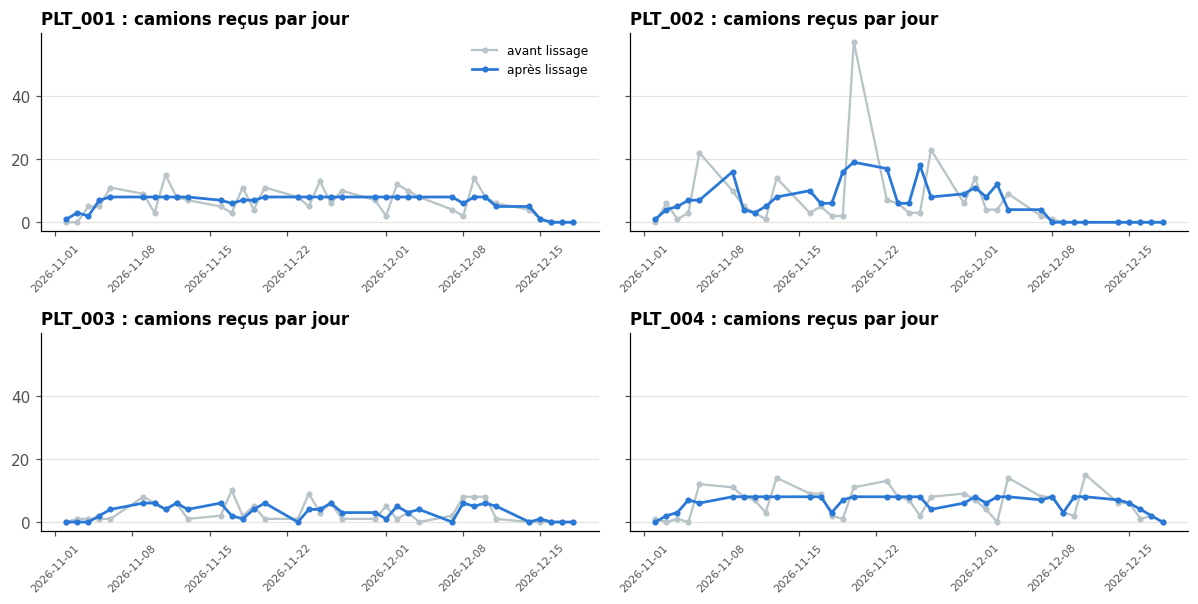

,couples,couples déplacés,pic avant (camions/jour),pic après (camions/jour),coût avant (EUR),coût après (EUR),surcoût (%),statut
usine,,,,,,,,
PLT_001,51,22,15,8,27 670.90,27 693.51,0.08,Optimal Solution Found
PLT_002,64,31,57,19,28 496.70,28 776.09,0.98,Optimal Solution Found
PLT_003,26,11,10,6,19 232.51,19 333.56,0.53,Optimal Solution Found
PLT_004,39,22,15,8,34 222.66,34 461.45,0.70,Optimal Solution Found


In [9]:
start = time.perf_counter()
first_pass = {(s, p): sol for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
options = build_options(instances, first_pass, CALENDAR, SETTINGS, workers=cfg.workers)
smoothing = {
    plant: smooth_plant(plant, {key: opts for key, opts in options.items() if key[1] == plant}, cfg.smoothing_tolerance)
    for plant in sorted({key[1] for key in options})
}
smoothed: dict[tuple[str, str], CoupleOption] = {key: opt for res in smoothing.values() for key, opt in res.chosen.items()}
logger.info("Smoothing in %.0f s: %d weekday sets priced for %d couples", time.perf_counter() - start,
            sum(len(opts) for opts in options.values()), len(options))

couples["weekdays_first_pass"] = couples["weekdays"]
couples["plan"] = [smoothed[s, p].plan for s, p in couples[list(cfg.couple_key)].itertuples(index=False)]
couples["weekdays"] = couples["plan"].map(lambda sol: ", ".join(WEEKDAYS[d] for d in sol.weekdays))
couples["moved"] = couples["weekdays"] != couples["weekdays_first_pass"]
assert (couples["plan"].map(lambda sol: len(sol.weekdays)) == couples["profile"]).all(), "smoothing changed a profile"


def daily_trucks(choice: dict[tuple[str, str], CoupleOption]) -> pd.Series:
    """Trucks received by each plant on each day for one weekday set per couple."""
    rows = [{"plant": key[1], "day": pd.Timestamp(day), "trucks": int(n)}
            for key, opt in choice.items() for day, n in zip(opt.days, opt.trucks, strict=True)]
    return pd.DataFrame(rows).groupby(["plant", "day"])["trucks"].sum()


plant_load = pd.DataFrame({
    "avant lissage": daily_trucks({key: opts[0] for key, opts in options.items()}),
    "après lissage": daily_trucks(smoothed),
}).reindex(pd.MultiIndex.from_product([sorted(smoothing), DELIVERY_DAYS], names=["plant", "day"])).fillna(0).astype(int)
smoothing_summary = pd.DataFrame([{
    "usine": res.plant, "couples": len(res.chosen), "couples déplacés": int(couples.loc[couples["plant"] == res.plant, "moved"].sum()),
    "pic avant (camions/jour)": res.peak_before, "pic après (camions/jour)": res.peak_after,
    "coût avant (EUR)": res.cost_before, "coût après (EUR)": res.cost_after,
    "surcoût (%)": 100 * (res.cost_after / res.cost_before - 1), "statut": res.status,
} for res in smoothing.values()]).set_index("usine")

fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharey=True)
for ax, (plant, load) in zip(axes.flat, plant_load.groupby(level="plant"), strict=True):
    days = load.index.get_level_values("day")
    ax.plot(days, load["avant lissage"], color="#b8c4c8", lw=1.5, marker="o", ms=3, label="avant lissage")
    ax.plot(days, load["après lissage"], color=PRIMARY, lw=1.8, marker="o", ms=3, label="après lissage")
    ax.set_title(f"{plant} : camions reçus par jour")
    ax.tick_params(axis="x", labelsize=7, rotation=45)
axes.flat[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
smoothing_summary

## 6. Plan optimisé et comparaison avec la situation actuelle

Le plan retenu (après lissage) est contrôlé règle par règle, chargé camion par camion (section 2.2), puis comparé à la situation actuelle chargée de la même façon, au total et par usine.

In [10]:
chosen_plans = {(s, p): sol for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
plan = needs.assign(delivery_date=delivery_dates(chosen_plans))
plan["anticipation_days"] = (plan["date"] - plan["delivery_date"]).dt.days
trucks, plan["truck_no"] = load_plan(plan)
deliveries = build_deliveries(plan, trucks)
deliveries["week"] = deliveries["delivery_date"] - pd.to_timedelta(deliveries["delivery_date"].dt.dayofweek, unit="D")

# Rule checks on the final plan
per_week = deliveries.groupby([*cfg.couple_key, "week"]).size().rename("deliveries").reset_index()
per_week = per_week.merge(couples[[*cfg.couple_key, "profile"]], on=list(cfg.couple_key), validate="m:1")
assert plan["delivery_date"].notna().all() and len(plan) == len(needs), "RG08: a line is not delivered"
assert plan["anticipation_days"].between(0, cfg.max_anticipation_days).all(), "RG03: anticipation out of the window"
assert deliveries["delivery_date"].isin(DELIVERY_DAYS).all(), "RG10: delivery on a weekend or a holiday"
allowed_days = {(s, p): set(sol.weekdays) for s, p, sol in couples[[*cfg.couple_key, "plan"]].itertuples(index=False)}
on_allowed_day = [
    day.dayofweek in allowed_days[s, p]
    for s, p, day in deliveries[[*cfg.couple_key, "delivery_date"]].itertuples(index=False)
]
highest_frequency = per_week.groupby(list(cfg.couple_key)).agg(max_week=("deliveries", "max"), profile=("profile", "first"))
assert all(on_allowed_day), "RG05: delivery on a weekday that is not allowed by the profile"
assert (per_week["deliveries"] <= per_week["profile"]).all(), "RG05: more deliveries in a week than the profile"
assert (highest_frequency["max_week"] == highest_frequency["profile"]).all(), "RG05: profile wider than the highest weekly frequency"
assert np.isclose(deliveries["weight"].sum(), needs["weight"].sum()), "weight lost"
loaded_peak = trucks.groupby(["plant", "delivery_date"]).size().groupby(level="plant").max()
assert all(loaded_peak[p] <= smoothing[p].peak_before for p in smoothing), "RG09: smoothing raised a peak"


def kpis(d: pd.DataFrame) -> pd.Series:
    """Indicators of a set of deliveries (same definitions as milestone 2)."""
    return pd.Series({
        "livraisons": len(d),
        "camions": int(d["trucks"].sum()),
        "poids médian d'une livraison (kg)": d["weight"].median(),
        "remplissage médian (%)": 100 * d["fill"].median(),
        "coût total (EUR)": d["cost"].sum(),
    })


comparison = pd.DataFrame({"actuel": kpis(baseline_deliveries), "optimisé": kpis(deliveries)})
comparison["écart (%)"] = 100 * (comparison["optimisé"] / comparison["actuel"] - 1)
by_plant = pd.DataFrame({
    "coût actuel (EUR)": baseline_deliveries.groupby("plant")["cost"].sum(),
    "coût optimisé (EUR)": deliveries.groupby("plant")["cost"].sum(),
})
by_plant["saving (%)"] = 100 * (1 - by_plant["coût optimisé (EUR)"] / by_plant["coût actuel (EUR)"])
bias = pd.DataFrame({
    "estimateur Milestone 2 (EUR)": [baseline_deliveries["estimator_cost"].sum(), deliveries["estimator_cost"].sum()],
    "chargement camion par camion (EUR)": [BASELINE_COST, deliveries["cost"].sum()],
    "camions (chargement)": [len(baseline_trucks), len(trucks)],
}, index=["actuel", "optimisé"])
bias["écart (%)"] = 100 * (bias.iloc[:, 1] / bias.iloc[:, 0] - 1)
logger.info("Optimised plan: %.0f EUR vs current %.0f EUR (-%.1f %%), both loaded truck by truck",
            deliveries["cost"].sum(), BASELINE_COST, 100 * (1 - deliveries["cost"].sum() / BASELINE_COST))
logger.info("Loading: %d trucks, %d deliveries need more than one truck",
            len(trucks), (deliveries["trucks"] > 1).sum())
display(bias)
print("Anticipation des lignes (jours -> lignes) :", plan["anticipation_days"].value_counts().sort_index().to_dict())
display(by_plant)
comparison

16:30:56 INFO    Optimised plan: 110265 EUR vs current 176725 EUR (-37.6 %), both loaded truck by truck


16:30:56 INFO    Loading: 761 trucks, 54 deliveries need more than one truck


,estimateur Milestone 2 (EUR),chargement camion par camion (EUR),camions (chargement),écart (%)
actuel,176 979.32,176 724.61,1741,-0.14
optimisé,110 540.83,110 264.61,761,-0.25


Anticipation des lignes (jours -> lignes) : {0: 858, 1: 524, 2: 447, 3: 467, 4: 440, 5: 348, 6: 480, 7: 825}


,coût actuel (EUR),coût optimisé (EUR),saving (%)
plant,,,
PLT_001,45 200.68,27 693.51,38.73
PLT_002,45 004.43,28 776.09,36.06
PLT_003,27 931.81,19 333.56,30.78
PLT_004,58 587.68,34 461.45,41.18


,actuel,optimisé,écart (%)
livraisons,1 665.00,653.00,-60.78
camions,1 741.00,761.00,-56.29
poids médian d'une livraison (kg),349.64,831.28,137.75
remplissage médian (%),1.61,3.61,124.85
coût total (EUR),176 724.61,110 264.61,-37.61


## 6.1 Avant optimisation, après optimisation, après lissage

Trois états du plan, tous chargés camion par camion :
- **actuel :** chaque ligne livrée le jour de son besoin (Milestone 2) ;
- **après optimisation :** plan de la première passe (profils choisis, jours non lissés) ;
- **après lissage :** plan final, après la deuxième passe (section 5.2).

Les graphiques comparent le coût, le nombre de livraisons et de camions, le coût et le pic de camions par usine, puis la répartition des camions sur les jours de la semaine.

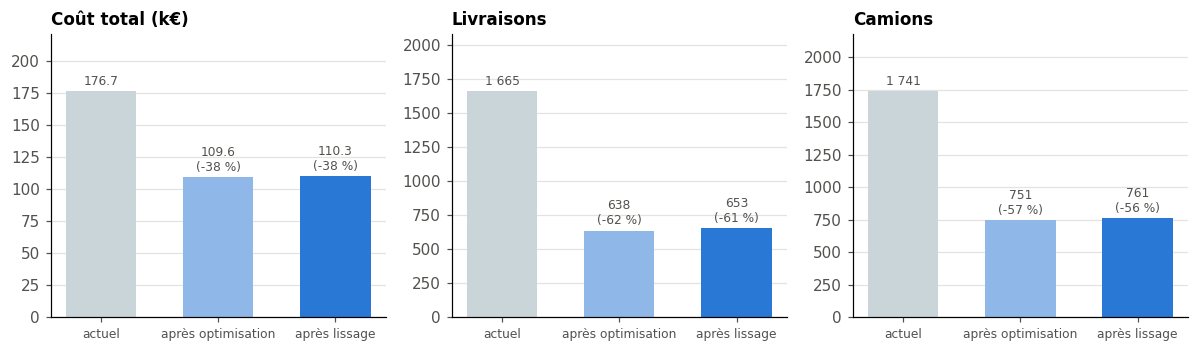

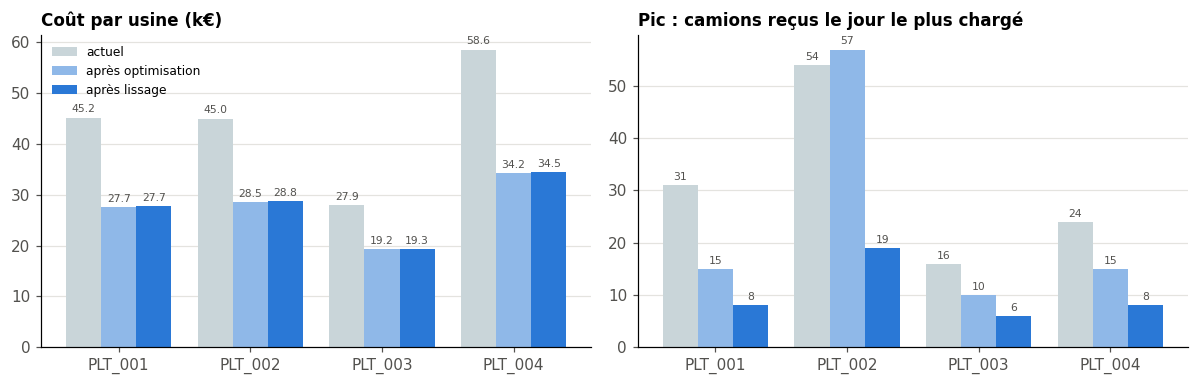

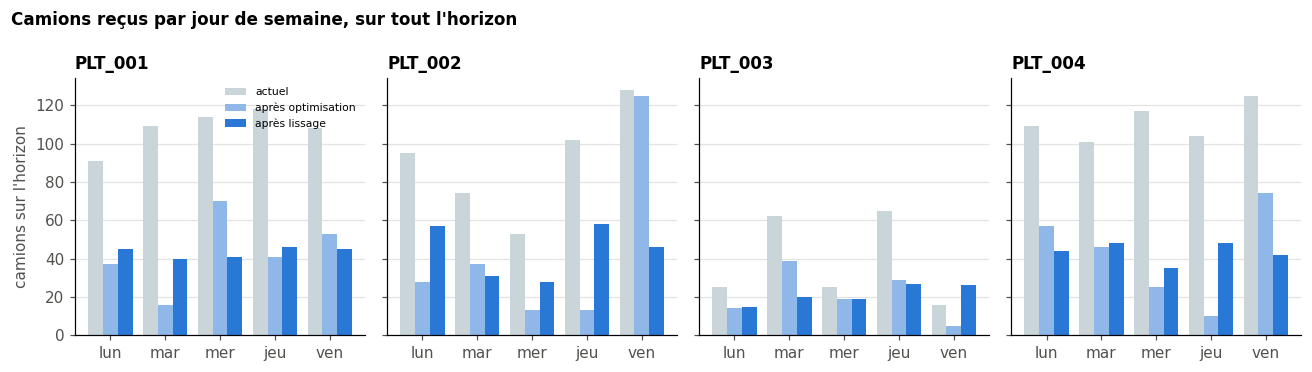

,coût total (EUR),livraisons,camions,pic max d'une usine (camions/jour)
actuel,176 724.61,1665,1741,54
après optimisation,109 622.78,638,751,57
après lissage,110 264.61,653,761,19


In [11]:
STATES = ["actuel", "après optimisation", "après lissage"]
STATE_COLORS = ["#c9d5d9", "#8fb8e8", PRIMARY]
first_pass_choice = {key: opts[0] for key, opts in options.items()}  # option 0 = plan of the first pass
plants = sorted(smoothing)

daily_by_state = {  # trucks received per plant and per day
    "actuel": baseline_trucks.groupby(["plant", "delivery_date"]).size(),
    "après optimisation": daily_trucks(first_pass_choice).rename_axis(["plant", "delivery_date"]),
    "après lissage": trucks.groupby(["plant", "delivery_date"]).size(),
}
plant_cost = pd.DataFrame({
    "actuel": baseline_deliveries.groupby("plant")["cost"].sum(),
    "après optimisation": pd.Series({p: sum(o.cost for k, o in first_pass_choice.items() if k[1] == p) for p in plants}),
    "après lissage": deliveries.groupby("plant")["cost"].sum(),
})[STATES]
states = pd.DataFrame({
    "coût total (EUR)": plant_cost.sum(),
    "livraisons": pd.Series([len(baseline_deliveries), sum(len(o.days) for o in first_pass_choice.values()),
                             len(deliveries)], index=STATES),
    "camions": pd.Series({s: int(d.sum()) for s, d in daily_by_state.items()}),
    "pic max d'une usine (camions/jour)": pd.Series({s: int(d.max()) for s, d in daily_by_state.items()}),
})
peaks = pd.DataFrame({s: d.groupby(level="plant").max() for s, d in daily_by_state.items()})[STATES]
assert np.isclose(states.loc["après lissage", "coût total (EUR)"], deliveries["cost"].sum()), "state costs mismatch"


def grouped_bars(ax: plt.Axes, table: pd.DataFrame, fmt: str = "{:,.0f}") -> None:
    """Grouped bars: one group per row of the table, one bar per state (column)."""
    pos = np.arange(len(table))
    width = 0.8 / len(table.columns)
    for i, (state, color) in enumerate(zip(table.columns, STATE_COLORS, strict=True)):
        bars = ax.bar(pos + (i - 1) * width, table[state], width=width, color=color, label=state)
        ax.bar_label(bars, labels=[fmt.format(v).replace(",", " ") for v in table[state]], padding=2, fontsize=7,
                     color=MUTED)
    ax.set_xticks(pos, table.index)


# 1. Totals
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (column, title, scale) in zip(axes, [("coût total (EUR)", "Coût total (k€)", 1000),
                                             ("livraisons", "Livraisons", 1), ("camions", "Camions", 1)], strict=True):
    values = states[column] / scale
    bars = ax.bar(STATES, values, color=STATE_COLORS, width=0.6)
    labels = [f"{v:,.1f}".replace(",", " ") if scale > 1 else f"{v:,.0f}".replace(",", " ") for v in values]
    labels = [lab if s == "actuel" else f"{lab}\n({100 * (v / values.iloc[0] - 1):+.0f} %)"
              for lab, s, v in zip(labels, STATES, values, strict=True)]
    ax.bar_label(bars, labels=labels, padding=2, fontsize=8, color=MUTED)
    ax.set_title(title); ax.set_ylim(0, values.max() * 1.25); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()

# 2. Per plant: cost and daily truck peak
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
grouped_bars(axes[0], plant_cost / 1000, "{:,.1f}")
axes[0].set_title("Coût par usine (k€)"); axes[0].legend(fontsize=8)
grouped_bars(axes[1], peaks)
axes[1].set_title("Pic : camions reçus le jour le plus chargé")
plt.tight_layout(); plt.show()

# 3. Trucks per weekday and per plant over the whole horizon
fig, axes = plt.subplots(1, len(plants), figsize=(12, 3.4), sharey=True)
for ax, plant in zip(axes, plants, strict=True):
    by_weekday = pd.DataFrame({
        s: d.loc[plant].groupby(d.loc[plant].index.dayofweek).sum() for s, d in daily_by_state.items()
    }).reindex(range(5), fill_value=0).fillna(0)[STATES]
    by_weekday.index = [WEEKDAYS[i][:3] for i in by_weekday.index]
    pos = np.arange(5)
    for i, (state, color) in enumerate(zip(STATES, STATE_COLORS, strict=True)):
        ax.bar(pos + (i - 1) * 0.27, by_weekday[state], width=0.27, color=color, label=state)
    ax.set_xticks(pos, by_weekday.index); ax.set_title(plant)
axes[0].legend(fontsize=7); axes[0].set_ylabel("camions sur l'horizon")
fig.suptitle("Camions reçus par jour de semaine, sur tout l'horizon", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
states

## 6.2 Sortie 2 : les articles regroupés dans chaque camion

Pour chaque camion (couple + jour + n°), la liste des articles qu'il transporte : quai, jours de besoin regroupés, quantité, poids et volume. Une ligne du tableau = un article × un quai dans un camion.
- Le fichier complet est exporté dans `optimized_truck_materials.csv` (section 7).
- Ci-dessous, l'exemple de la présentation : le camion de SUP_00085 × PLT_004 la semaine du 16/11.
- « Remplace » = nombre de livraisons actuelles (couple × jour de besoin) dont les lignes partent dans ce camion.

In [12]:
def truck_materials(plan: pd.DataFrame) -> pd.DataFrame:
    """Output 2: one row per truck x material x unloading point, with the days of need it groups."""
    keys = [*cfg.couple_key, "delivery_date", "truck_no", "material", "unloading_point"]
    content = (
        plan.groupby(keys)
        .agg(need_days=("date", lambda days: ", ".join(f"{d:%d/%m}" for d in sorted(set(days)))),
             lines=("line_id", "size"), quantity=("schedule_quantity", "sum"),
             weight=("weight", "sum"), volume=("volume", "sum"))
        .reset_index()
    )
    order = [*cfg.couple_key, "delivery_date", "truck_no", "weight"]
    return content.sort_values(order, ascending=[True] * (len(order) - 1) + [False], ignore_index=True)


truck_content = truck_materials(plan)
assert np.isclose(truck_content["weight"].sum(), needs["weight"].sum()), "Output 2: weight lost"
assert truck_content["lines"].sum() == len(needs), "Output 2: a line is missing"

# Example of the presentation: the heaviest truck of SUP_00085 x PLT_004 in the week of 16/11/2026
EXAMPLE_COUPLE, EXAMPLE_WEEK = ("SUP_00085", "PLT_004"), pd.Timestamp("2026-11-16")
week_trucks = trucks[(trucks["supplier_id"] == EXAMPLE_COUPLE[0]) & (trucks["plant"] == EXAMPLE_COUPLE[1])
                     & trucks["delivery_date"].between(EXAMPLE_WEEK, EXAMPLE_WEEK + pd.Timedelta(days=4))]
assert not week_trucks.empty, "the example couple has no truck in the example week"
truck = week_trucks.loc[week_trucks["weight"].idxmax()]


def is_example_truck(frame: pd.DataFrame) -> pd.Series:
    """Rows of a frame that belong to the example truck."""
    return ((frame["supplier_id"] == truck["supplier_id"]) & (frame["plant"] == truck["plant"])
            & (frame["delivery_date"] == truck["delivery_date"]) & (frame["truck_no"] == truck["truck_no"]))


in_truck = plan[is_example_truck(plan)]
example = truck_content[is_example_truck(truck_content)]

logger.info("Output 2 example: %s x %s, truck %d of %s | %d materials, %d lines | %.1f t (%.1f %%), %.1f m3 (%.1f %%) "
            "| %.0f EUR | replaces %d current deliveries", truck["supplier_id"], truck["plant"], truck["truck_no"],
            truck["delivery_date"].date(), len(example), len(in_truck), truck["weight"] / 1000,
            100 * truck["fill_weight"], truck["volume"], 100 * truck["fill_volume"], truck["cost"],
            in_truck["date"].nunique())
shown = example[["material", "unloading_point", "need_days", "lines", "quantity", "weight", "volume"]].rename(columns={
    "material": "article", "unloading_point": "quai", "need_days": "besoins regroupés", "lines": "lignes",
    "quantity": "quantité", "weight": "poids (kg)", "volume": "volume (m³)",
})
total = pd.DataFrame([{"article": "Total camion", "quai": "", "besoins regroupés": f"{len(in_truck)} lignes de besoin",
                       "lignes": shown["lignes"].sum(), "quantité": shown["quantité"].sum(),
                       "poids (kg)": shown["poids (kg)"].sum(), "volume (m³)": shown["volume (m³)"].sum()}])
pd.concat([shown, total], ignore_index=True)

16:30:57 INFO    Output 2 example: SUP_00085 x PLT_004, truck 1 of 2026-11-16 | 16 materials, 31 lines | 9.7 t (39.7 %), 28.0 m3 (25.4 %) | 331 EUR | replaces 5 current deliveries


,article,quai,besoins regroupés,lignes,quantité,poids (kg),volume (m³)
0,MAT_000298,ULP_0010,"17/11, 18/11, 19/11, 20/11",4,1 014.00,3 254.10,3.16
1,MAT_000074,ULP_0050,"17/11, 18/11, 19/11, 20/11",4,1 200.00,1 100.40,4.80
2,MAT_000455,ULP_0050,"17/11, 18/11, 20/11",3,1 350.00,977.10,2.67
3,MAT_000131,ULP_0010,"17/11, 20/11",2,240.00,697.60,1.58
4,MAT_000966,ULP_0050,"17/11, 20/11",2,1 200.00,526.80,2.40
5,MAT_000103,ULP_0050,19/11,1,750.00,468.50,1.20
6,MAT_000621,ULP_0050,17/11,1,450.00,385.10,1.20
7,MAT_000505,ULP_0050,20/11,1,4 000.00,337.60,1.20
8,MAT_000808,ULP_0050,19/11,1,1 000.00,331.40,0.57
9,MAT_000270,ULP_0050,"16/11, 17/11, 19/11",3,870.00,304.80,1.71


## 7. Export

| Fichier | Une ligne = | Usage |
| :--- | :--- | :--- |
| `optimized_lines.csv` | une ligne de besoin, avec son jour de livraison, son anticipation et son camion (`truck_no`) | plan détaillé (Sortie 2) |
| `optimized_trucks.csv` | un camion (couple + jour + n°), avec lignes, articles, quais, poids, volume, remplissage et coût | camions (Sortie 2) |
| `optimized_truck_materials.csv` | un article × un quai dans un camion, avec les jours de besoin regroupés, la quantité, le poids et le volume | articles regroupés dans chaque camion (Sortie 2) |
| `optimized_deliveries.csv` | une livraison (couple × jour), avec charge, camions et coût | camions et coûts (Sortie 2, 3) |
| `optimized_couples.csv` | un couple : profil, jours de livraison après lissage (et avant : `weekdays_first_pass`), coût pour chaque $N$ | profils (Sortie 1), règle RG07 modifiable |
| `optimized_plant_load.csv` | une usine × un jour : camions reçus avant et après lissage | lissage (RG09) |
| `optimized_kpis.csv` | un indicateur, actuel et optimisé | économie (Sortie 3) |

In [13]:
cfg.output_dir.mkdir(parents=True, exist_ok=True)
baseline_cost = baseline_deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("baseline_cost")
optimised_cost = deliveries.groupby(list(cfg.couple_key))["cost"].sum().rename("optimised_cost")
couples_out = (couples.drop(columns="plan")
               .merge(baseline_cost.reset_index(), on=list(cfg.couple_key), validate="1:1")
               .merge(optimised_cost.reset_index(), on=list(cfg.couple_key), validate="1:1"))
couples_out["saving"] = couples_out["baseline_cost"] - couples_out["optimised_cost"]

plan.to_csv(cfg.output_dir / "optimized_lines.csv", index=False, date_format="%Y-%m-%d")
deliveries.to_csv(cfg.output_dir / "optimized_deliveries.csv", index=False, date_format="%Y-%m-%d")
trucks.to_csv(cfg.output_dir / "optimized_trucks.csv", index=False, date_format="%Y-%m-%d")
truck_content.to_csv(cfg.output_dir / "optimized_truck_materials.csv", index=False, date_format="%Y-%m-%d")
couples_out.to_csv(cfg.output_dir / "optimized_couples.csv", index=False)
comparison.to_csv(cfg.output_dir / "optimized_kpis.csv", index_label="indicator")
plant_load.to_csv(cfg.output_dir / "optimized_plant_load.csv", date_format="%Y-%m-%d")
logger.info("Files written to %s", cfg.output_dir.resolve().name)

couples_out.sort_values("saving", ascending=False).head(15)

16:30:57 INFO    Files written to data


,supplier_id,plant,n_max,profile,weekdays,cost_N1,cost_N2,cost_N3,cost_N4,cost_N5,weekdays_first_pass,moved,baseline_cost,optimised_cost,saving
83,SUP_00085,PLT_004,1,1,lundi,1 988.44,1 988.44,1 988.44,1 988.44,1 988.44,lundi,False,7 429.18,1 988.44,5 440.74
159,SUP_00146,PLT_002,2,2,"lundi, mardi",1 416.90,1 379.27,1 379.27,1 379.27,1 379.27,"lundi, mardi",False,4 651.48,1 151.09,3 500.39
58,SUP_00059,PLT_003,1,1,mercredi,1 587.59,1 587.59,1 587.59,1 587.59,1 587.59,mercredi,False,3 874.58,1 587.59,2 286.99
152,SUP_00144,PLT_001,2,2,"lundi, mercredi",1 429.22,1 283.49,1 283.49,1 283.49,1 283.49,"lundi, mercredi",False,3 454.61,1 283.49,2 171.12
78,SUP_00080,PLT_004,1,1,vendredi,1 179.94,1 179.94,1 179.94,1 179.94,1 179.94,vendredi,False,2 989.46,1 179.94,1 809.53
123,SUP_00118,PLT_001,1,1,vendredi,1 451.38,1 451.38,1 451.38,1 451.38,1 451.38,vendredi,False,3 210.51,1 451.38,1 759.13
157,SUP_00145,PLT_004,2,2,"lundi, vendredi",1 403.17,1 356.25,1 356.25,1 356.25,1 356.25,"lundi, vendredi",False,3 033.99,1 356.25,1 677.74
139,SUP_00129,PLT_003,3,3,"lundi, mercredi, vendredi",8 537.16,8 537.16,8 392.93,8 392.93,8 392.93,"lundi, mardi, mercredi",True,10 143.87,8 477.40,1 666.47
89,SUP_00087,PLT_004,1,1,lundi,1 402.08,1 402.08,1 402.08,1 402.08,1 402.08,vendredi,True,2 995.95,1 404.51,1 591.44
9,SUP_00011,PLT_004,1,1,lundi,1 282.64,1 282.64,1 282.64,1 282.64,1 282.64,vendredi,True,2 861.52,1 282.64,1 578.88


## Synthèse

- **Validation :** sans anticipation (fenêtre de 0 jour), le moteur retrouve exactement les 1 665 livraisons actuelles, et l'estimateur du Milestone 2 redonne 176 979 € : on part des mêmes données.
- **Chargement camion par camion :** chaque ligne part entière dans un seul camion (au plus 24,5 t et 110,4 m³), avec d'abord le moins de camions possible, puis le coût le plus bas. Chaque camion est facturé sur son propre poids. La situation actuelle, rechargée ainsi, coûte **176 725 €** pour 1 741 camions : l'estimateur du Milestone 2 surestimait de 0,14 %.
- **Profils resserrés (contrainte 8) :** le nombre de jours autorisés d'un couple est égal à sa fréquence max réellement atteinte. **130 couples à 1 livraison par semaine, 47 à 2, 3 à 3**, et aucun à 4 ou 5. Aujourd'hui, 31 couples sont livrés jusqu'à 5 fois par semaine.
- **Lissage par usine (RG09) :** sans lissage, l'optimisation seule regroupe les livraisons sur quelques jours, et le pic d'une usine monte même un peu (54 camions sur un jour aujourd'hui, 57 après la première passe). Avec le lissage, 86 couples changent de jours, sans changer de profil. Le pic de camions reçus sur un jour passe de **57 à 19 pour PLT_002**, de 15 à 8 pour PLT_001 et PLT_004, et de 10 à 6 pour PLT_003. Le lissage coûte **+0,6 %** (109 623 € → 110 265 €), sous la limite de 1 % par usine (`smoothing_tolerance`). La section 6.1 compare les trois états en graphiques.
- **Plan final : 110 265 €, soit −37,6 %** par rapport à la situation actuelle chargée de la même façon. C'est mieux que le scénario « 1 livraison par semaine » du Milestone 2 (121 406 €, −31 %).
- **Livraisons : 1 665 → 653 (−61 %)**, camions 1 741 → 761 (−56 %), dont 54 livraisons de plus d'un camion. Le poids médian d'une livraison passe de 350 à 831 kg. Le saving va de 31 % (PLT_003) à 41 % (PLT_004).
- **Sortie 2 (articles par camion) :** `optimized_truck_materials.csv` donne, pour chaque camion, ses articles, quais, jours de besoin regroupés, quantités, poids et volumes. Exemple : le camion de SUP_00085 × PLT_004 du lundi 16/11 regroupe 16 articles (31 lignes, 9,7 t, 28 m³) et remplace 5 livraisons actuelles.
- **Temps de calcul : environ 2 min 40 s** au total : 900 problèmes en première passe (environ 105 s, 5 s au plus chacun, 12 cœurs), puis environ 40 s pour le lissage. Une vingtaine de résolutions s'arrêtent sur la limite de temps avec une bonne solution : d'une exécution à l'autre, les chiffres peuvent varier d'environ 0,1 %.
- **À trancher avec le client :** la règle de choix du profil (RG07) et le surcoût accepté pour le lissage. Le coût de chaque profil est dans `optimized_couples.csv` (colonnes `cost_N1` à `cost_N5`, coût du modèle avant chargement).